# Projet Data-Driven Decision Making
## Analyse des transactions e-commerce et du comportement client

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap


## Chargement des datasets

In [2]:
data_Orders = pd.read_csv(
    "../../shared_data/data_Orders.csv",
    encoding="latin1"
)

customers = pd.read_csv(
    "../../shared_data/Customers.csv",
    sep="\t",
    encoding="latin1"
)

## Préparation des données

Mêmes étapes que dans le notebook d'analyse : valeurs manquantes de `Income` remplacées par la moyenne, création de `Age` et `Total_Spending`.

In [3]:
customers = customers.drop_duplicates()
customers["Income"] = customers["Income"].fillna(customers["Income"].mean())

customers["Age"] = 2026 - customers["Year_Birth"]

customers["Total_Spending"] = (
    customers["MntWines"] +
    customers["MntFruits"] +
    customers["MntMeatProducts"] +
    customers["MntFishProducts"] +
    customers["MntSweetProducts"] +
    customers["MntGoldProds"]
)

# 5. Modélisation & Machine Learning

## 5.1 Préparation des données pour la prédiction

In [4]:
#Créer le dataset ML
ml_data = customers[[
    "Income",
    "Age",
    "Total_Spending",
    "NumWebPurchases",
    "NumStorePurchases",
    "Response"
]]

ml_data.head()

,Income,Age,Total_Spending,NumWebPurchases,NumStorePurchases,Response
0,58138.0,69,1617,8,4,1
1,46344.0,72,27,1,2,0
2,71613.0,61,776,8,10,0
3,26646.0,42,53,2,4,0
4,58293.0,45,422,5,6,0


### Préparation des données Machine Learning

Les variables sélectionnées permettront de prédire la réponse des clients aux campagnes marketing.

Les variables utilisées représentent :
- le revenu,
- l’âge,
- les dépenses,
- les achats web,
- les achats en magasin.

La variable cible est `Response`.

In [5]:
#Séparer X et y
X = ml_data.drop("Response", axis=1)

y = ml_data["Response"]

X	variables explicatives
-----------------y	variable cible à prédire

In [6]:
#Vérifier
X.head()

,Income,Age,Total_Spending,NumWebPurchases,NumStorePurchases
0,58138.0,69,1617,8,4
1,46344.0,72,27,1,2
2,71613.0,61,776,8,10
3,26646.0,42,53,2,4
4,58293.0,45,422,5,6


In [7]:
y.head()

0    1
1    0
2    0
3    0
4    0
Name: Response, dtype: int64

## 5.2 Séparation des données (Train/Test Split)

In [8]:
#Importer train_test_split
from sklearn.model_selection import train_test_split

In [9]:
#Séparer les données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### Explication du Train/Test Split

Les données ont été divisées en deux parties afin d’évaluer les performances du modèle Machine Learning.

Les variables explicatives (`X`) contiennent les informations utilisées pour effectuer les prédictions, tandis que la variable cible (`y`) représente la réponse des clients aux campagnes marketing.

La fonction `train_test_split()` permet de :
- utiliser 80% des données pour l’entraînement du modèle,
- réserver 20% des données pour le test et l’évaluation.

Le paramètre `random_state=42` garantit des résultats reproductibles à chaque exécution.

Les ensembles obtenus sont :
- `X_train` et `y_train` pour entraîner le modèle,
- `X_test` et `y_test` pour tester les performances du modèle sur des données non vues.

In [10]:
#Vérifier les dimensions
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1792, 5)
(448, 5)
(1792,)
(448,)


### Interprétation du Train/Test Split

Les données ont été séparées en deux ensembles :
- un ensemble d’entraînement (80%),
- un ensemble de test (20%).

L’ensemble d’entraînement sera utilisé pour apprendre le modèle Machine Learning, tandis que l’ensemble de test permettra d’évaluer ses performances sur des données non vues.

## 5.3 Modèle de Logistic Regression

In [11]:
#Importer Logistic Regression
from sklearn.linear_model import LogisticRegression

In [12]:
#Créer le modèle
model = LogisticRegression(max_iter=1000)

In [13]:
#Entraîner le modèle
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [14]:
#Faire les prédictions
y_pred = model.predict(X_test)

### Explication du modèle Logistic Regression

Le modèle de Logistic Regression a été utilisé pour prédire la réponse des clients aux campagnes marketing.

Ce modèle est adapté aux problèmes de classification binaire où la variable cible possède deux classes :
- 0 : le client ne répond pas,
- 1 : le client répond à la campagne.

Le modèle apprend les relations entre les caractéristiques des clients et leur comportement marketing afin de réaliser des prédictions.

## 5.4 Évaluation du modèle

In [15]:
#Accuracy du modèle
from sklearn.metrics import accuracy_score

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.8571428571428571


### Interprétation de l’Accuracy

L’accuracy mesure la capacité du modèle à prédire correctement la réponse des clients aux campagnes marketing.

Une accuracy élevée indique que le modèle est capable d’identifier efficacement les clients susceptibles de répondre positivement aux campagnes.

In [17]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

In [18]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[375,   4],
       [ 60,   9]])

### Explication de la Confusion Matrix

La confusion matrix permet de comparer les prédictions du modèle avec les valeurs réelles.

Elle contient quatre types de résultats :

- Vrai positif (True Positive) :
  le modèle prédit correctement qu’un client répondra à la campagne.

- Vrai négatif (True Negative) :
  le modèle prédit correctement qu’un client ne répondra pas.

- Faux positif (False Positive) :
  le modèle prédit qu’un client répondra alors que ce n’est pas le cas.

- Faux négatif (False Negative) :
  le modèle prédit qu’un client ne répondra pas alors qu’il répond réellement.

Cette matrice permet d’évaluer les erreurs du modèle et la qualité globale des prédictions.

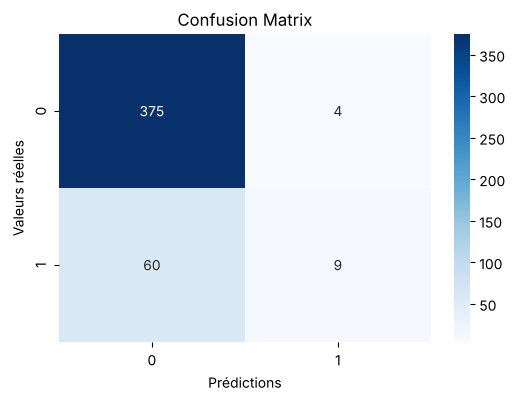

In [19]:
#Afficher la matrice joliment
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")

plt.show()

### Interprétation de la Confusion Matrix

La confusion matrix permet d’évaluer les performances du modèle en comparant les prédictions avec les valeurs réelles.

Les valeurs diagonales représentent les prédictions correctes, tandis que les autres valeurs correspondent aux erreurs de classification.

Cette analyse permet de mesurer la qualité du modèle et d’identifier les types d’erreurs réalisées.

In [20]:
#Classification Report
from sklearn.metrics import classification_report

In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.99      0.92       379
           1       0.69      0.13      0.22        69

    accuracy                           0.86       448
   macro avg       0.78      0.56      0.57       448
weighted avg       0.84      0.86      0.81       448



### Interprétation du Classification Report

Le classification report fournit plusieurs métriques permettant d’évaluer les performances du modèle :
- la précision (qualité des prédictions),
- le recall (capacité à retrouver les vrais positifs),
- le F1-score (équilibre précision/rappel).

Ces indicateurs permettent de mieux comprendre la capacité du modèle à détecter correctement les clients répondant aux campagnes marketing.

## 5.5 Importance des variables

In [22]:
#Afficher les coefficients du modèle
importance = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_[0]
})

importance

,Variable,Coefficient
0,Income,-0.000010
1,Age,-0.007063
2,Total_Spending,0.001765
3,NumWebPurchases,0.088491
4,NumStorePurchases,-0.167218


In [23]:
#Trier les variables importantes
importance = importance.sort_values(
    by="Coefficient",
    ascending=False
)

importance

,Variable,Coefficient
3,NumWebPurchases,0.088491
2,Total_Spending,0.001765
0,Income,-0.000010
1,Age,-0.007063
4,NumStorePurchases,-0.167218


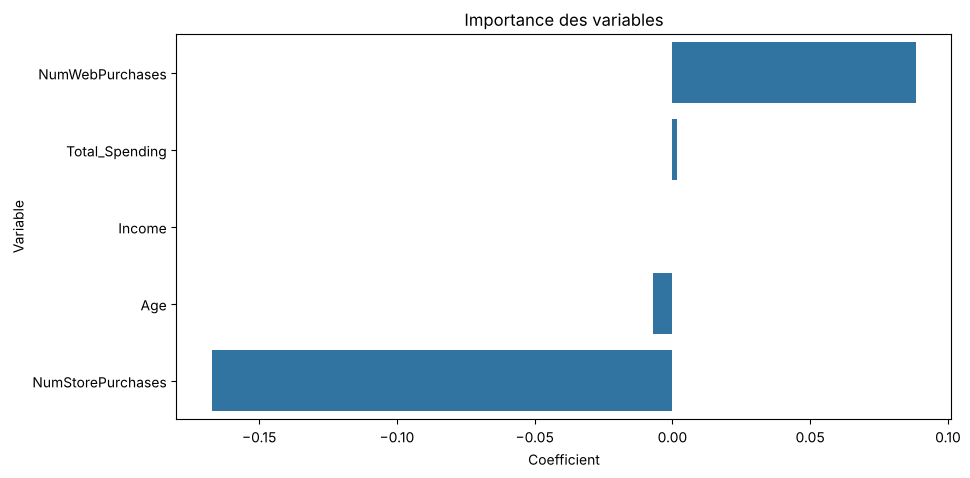

In [24]:
#Visualisation
plt.figure(figsize=(10,5))

sns.barplot(
    data=importance,
    x="Coefficient",
    y="Variable"
)

plt.title("Importance des variables")

plt.show()

### Interprétation de l’importance des variables

Les coefficients du modèle permettent d’identifier les variables ayant le plus d’influence sur la réponse des clients aux campagnes marketing.

Les variables ayant des coefficients positifs élevés augmentent la probabilité qu’un client réponde à une campagne.

À l’inverse, les coefficients négatifs indiquent une influence négative sur la réponse marketing.

Cette analyse permet de mieux comprendre les comportements clients et d’optimiser les stratégies marketing.

## 5.6 SHAP Explainability

In [25]:
#Créer l’explainer
explainer = shap.Explainer(model, X_train)

In [26]:
shap_values = explainer(X_test)

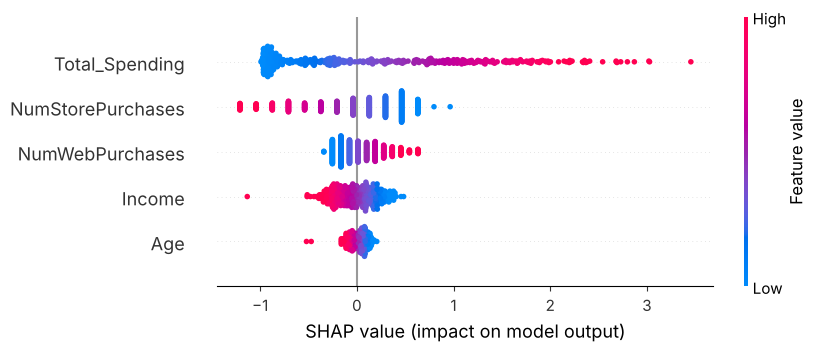

In [27]:
#Afficher le graphique SHAP
shap.plots.beeswarm(shap_values)

### Interprétation des résultats SHAP

Les valeurs SHAP permettent d’expliquer les décisions du modèle Machine Learning.

Le graphique met en évidence les variables ayant le plus d’impact sur les prédictions de réponse marketing.

Les variables les plus influentes contribuent positivement ou négativement à la probabilité qu’un client réponde à une campagne.

Cette approche améliore :
- l’interprétabilité du modèle,
- la compréhension métier,
- la confiance dans les prédictions réalisées.

## 5.7 Random Forest

In [28]:
#Ajouter un 2ème modèle -------Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy :", rf_accuracy)

Random Forest Accuracy : 0.84375


### Interprétation du modèle Random Forest

Le modèle Random Forest a été entraîné afin d’améliorer les performances de prédiction.

Ce modèle combine plusieurs arbres de décision afin de réduire les erreurs et améliorer la robustesse des prédictions.

In [30]:
#Ajouter un 3ème modèle ------Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [31]:
dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

print("Decision Tree Accuracy :", dt_accuracy)

Decision Tree Accuracy : 0.7678571428571429


### Interprétation du modèle Decision Tree

Le modèle Decision Tree utilise une structure arborescente afin de classifier les clients selon leurs caractéristiques.

Il permet d’identifier des règles simples expliquant les réponses marketing.

## 5.8 Comparaison des modèles

In [32]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree"
    ],
    
    "Accuracy": [
        accuracy,
        rf_accuracy,
        dt_accuracy
    ]
})

comparison

,Model,Accuracy
0,Logistic Regression,0.857143
1,Random Forest,0.843750
2,Decision Tree,0.767857


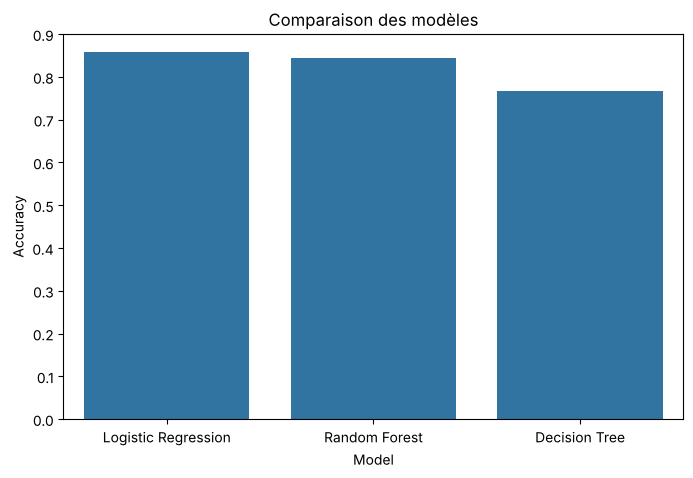

In [33]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Comparaison des modèles")

plt.show()

## 5.9 Validation croisée (k-fold)

In [34]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5
)

print(scores)
print(scores.mean())

[0.84821429 0.86607143 0.85267857 0.85491071 0.84821429]
0.8540178571428572


## 5.10 AUC-ROC

In [35]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:,1]

auc = roc_auc_score(
    y_test,
    y_prob
)

print("AUC-ROC :", auc)

AUC-ROC : 0.7147719016481205


## 5.11 Tuning des hyperparamètres

In [36]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur score :", grid_search.best_score_)

Meilleurs paramètres : {'max_depth': 3, 'n_estimators': 50}
Meilleur score : 0.8560277617839747


## 5.12 Interprétabilité locale avec SHAP

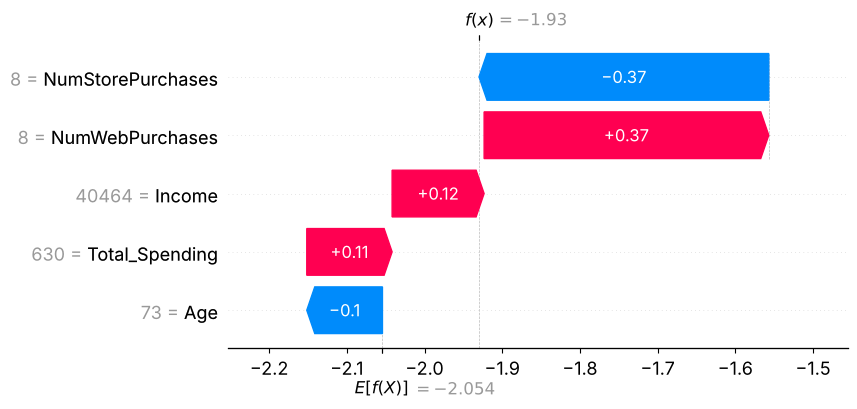

In [37]:
shap.plots.waterfall(shap_values[0])

### Interprétation locale avec SHAP

Le graphique SHAP local explique la prédiction réalisée pour un client spécifique.

Chaque variable contribue positivement ou négativement à la décision finale du modèle.

Cette approche permet de comprendre individuellement les facteurs influençant les prédictions.

# 6. Décision, A/B Testing & Mesure d'Impact

## 6.1 Recommandations actionnables

À partir des analyses réalisées, trois recommandations principales peuvent être proposées :

### Recommandation 1 — Cibler les clients à forte valeur

Les clients ayant un revenu élevé et un Total_Spending important doivent être ciblés en priorité avec des offres personnalisées.

Justification :
- ces clients génèrent une part importante du chiffre d’affaires,
- ils ont un fort potentiel de fidélisation,
- ils peuvent répondre positivement à des campagnes premium.

### Recommandation 2 — Optimiser les campagnes marketing

Le modèle Machine Learning permet d’identifier les clients les plus susceptibles de répondre aux campagnes marketing.

Justification :
- cela permet de réduire les coûts marketing,
- les campagnes deviennent plus ciblées,
- le taux de réponse peut être amélioré.

### Recommandation 3 — Prioriser les produits les plus rentables

Les produits et pays générant le plus de Revenue doivent être priorisés dans les décisions commerciales.

Justification :
- meilleure gestion du stock,
- meilleure allocation des ressources,
- augmentation potentielle du chiffre d’affaires.

## 6.2 Plan A/B Testing

### Objectif du test

Tester si une campagne marketing personnalisée augmente le taux de réponse des clients.

### Hypothèse nulle H0

La campagne personnalisée n’a aucun effet significatif sur le taux de réponse des clients.

### Hypothèse alternative H1

La campagne personnalisée augmente significativement le taux de réponse des clients.

### Groupes du test

- Groupe A : clients recevant une campagne standard.
- Groupe B : clients recevant une campagne personnalisée basée sur la segmentation et le modèle prédictif.

### Métriques suivies

- taux de réponse,
- chiffre d’affaires généré,
- panier moyen,
- taux de conversion,
- retour sur investissement marketing.

### Durée du test

Le test peut être réalisé sur une période de 2 semaines afin d’obtenir suffisamment de données pour comparer les deux groupes.

### Taille d’échantillon

Les clients seront répartis équitablement entre les deux groupes :
- 50% dans le groupe A,
- 50% dans le groupe B.

## 6.3 Mesure d’impact

Les métriques de suivi post-décision sont :

- évolution du chiffre d’affaires,
- taux de réponse aux campagnes,
- taux de conversion,
- panier moyen,
- nombre de clients actifs,
- satisfaction et fidélisation client.

L’impact attendu est :
- augmentation du chiffre d’affaires,
- amélioration du ciblage marketing,
- réduction des coûts liés aux campagnes inefficaces,
- meilleure fidélisation des clients à forte valeur.

## 6.4 Conclusion exécutive

Ce projet a permis de construire un système d’aide à la décision basé sur les données e-commerce et marketing.

Les analyses réalisées ont permis :
- d’identifier les clients à forte valeur,
- de segmenter les clients,
- de prédire la réponse aux campagnes marketing,
- de proposer des recommandations actionnables,
- de concevoir un dashboard décisionnel.

Ce système peut aider l’entreprise à améliorer ses décisions commerciales, optimiser ses campagnes marketing et augmenter son chiffre d’affaires.